# Synthetic biomarker benchmark — the shapes and what they settle

This notebook is the specification. Every shape below has values that follow from its geometry, and
those values are what a biomarker implementation is measured against — not another implementation's
opinion, and not a human's tracing.

**Why shapes at all.** A biomarker's name is not its definition: "tortuosity" names at least three
incompatible formulas, and papers usually report the name and omit the choice. Comparing two
programs tells you they differ without telling you which is right. A straight vessel has tortuosity
exactly 1, and that settles it.

**What it catches that a dataset cannot:** a factor of two in a curvature formula, a centreline
extractor that counts pixel steps where it should measure arc length, an arteriovenous ratio
computed from arteries alone, a measurement that moves when the vessel is rotated, a value invented
where the geometry offers none.

**Each shape is a retina stated in microns** — a 45° camera, a 1,800 µm optic disc, vessels as
networks of centrelines with known widths and curvature — and its ground truth is derived from that
geometry by clipping, integrating and counting, never from the pixels it is drawn as. The model and
the derivations are written out here so that what the shapes require is public and checkable: it is a reading of the catalogue's definitions, not of anybody's
implementation.

**Everything here is read from the store rather than drawn again.** The shapes are rendered once,
by `python -m benchmarks.shapes`, into `data/synthetic/av/`: a binary mask per class, a field of
view, a `manifest.csv` saying how each was framed, a `ground_truth.csv` holding the values each
one's geometry requires, and a `ground_truth_kind.csv` saying how each value is known. So the
pictures below are the very files a benchmark measures, not a second rendering that might differ.

How the benchmark is configured: [biomarker-synthetic-docs.md](../../docs/benchmarks/biomarker-synthetic-docs.md).
The rules the shapes follow: `.claude/skills/build-benchmark/biomarker-synthetic.md`.

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def repository() -> Path:
    """The repository, found rather than assumed."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src").is_dir():
            return candidate
    raise RuntimeError(f"nothing above {Path.cwd()} looks like the fundus-atlas repository")


ROOT = repository()
sys.path.insert(0, str(ROOT / "src"))

from benchmarks.shapes import library, render, scene, store, truth as derive  # noqa: E402
from biomarkers import canonical  # noqa: E402

STORE = ROOT / store.STORE
if not (STORE / "manifest.csv").exists():
    raise RuntimeError(f"no store at {STORE}: draw one with `python -m benchmarks.shapes`")

manifest = pd.DataFrame(store.read(STORE)).set_index("key")
truth = store.truth(STORE)
kinds = store.kinds(STORE)
undefined = store.undefined(STORE)

SIDE = int(manifest["side"].iloc[0])
UM_PER_PX = float(manifest["um_per_px"].iloc[0])
FAMILIES = list(dict.fromkeys(manifest["family"]))
ROTATIONS = sorted({float(angle) for angle in manifest["rotation"]})

print(f"{len(manifest)} renderings of {len(FAMILIES)} shapes, read from {STORE.relative_to(ROOT)}")
print(f"{SIDE}² px at {UM_PER_PX:.4g} µm per pixel — a frame {SIDE * UM_PER_PX / 1000:.2f} mm across, "
      f"a {scene.FOV_DEGREES:g}° field")
print(f"rotations: {', '.join(f'{angle:g}°' for angle in ROTATIONS)}")
print(f"arteries {scene.ARTERY_UM:g} µm, veins {scene.VEIN_UM:g} µm "
      f"({scene.ARTERY_UM / UM_PER_PX:.1f} and {scene.VEIN_UM / UM_PER_PX:.1f} px), "
      f"optic disc {scene.DISC_DIAMETER_UM:g} µm across")

91 renderings of 13 shapes, read from data/synthetic/av
2048² px at 6.328 µm per pixel — a frame 12.96 mm across, a 45° field
rotations: 0°, 15°, 30°, 45°, 60°, 75°, 90°
arteries 80 µm, veins 120 µm (12.6 and 19.0 px), optic disc 1800 µm across


## 1. The shapes

Each is drawn from centrelines in continuous coordinates and rasterised once — never drawn small and
enlarged, and never rotated as a picture, because resampling a structure a few pixels wide destroys
it. Turning is done to the geometry and the scene is drawn again, so the pixel grid is the only
difference between one angle and another. **A pixel is lit when its centre lies inside the drawn
vessel**, and pixel `i`'s centre is at `i` — the convention the disc is handed over in, and the one
every disc estimate in `results/disc_estimation/` uses.

**Arteries are red, veins are blue**, the field of view is the dark circle, the optic disc is the
gold ring, and the faint rings are two, three and five disc radii out: zone B is the annulus from two
to three, zone C from two to five.

**Every shape carries both classes.** A segmentation of a real eye has arteries and veins in it, so
a shape offering only one would test something no implementation ever meets; it also means every
shape pins the ratio of the two calibres, which is the one arteriovenous quantity needing neither
disc nor zone.

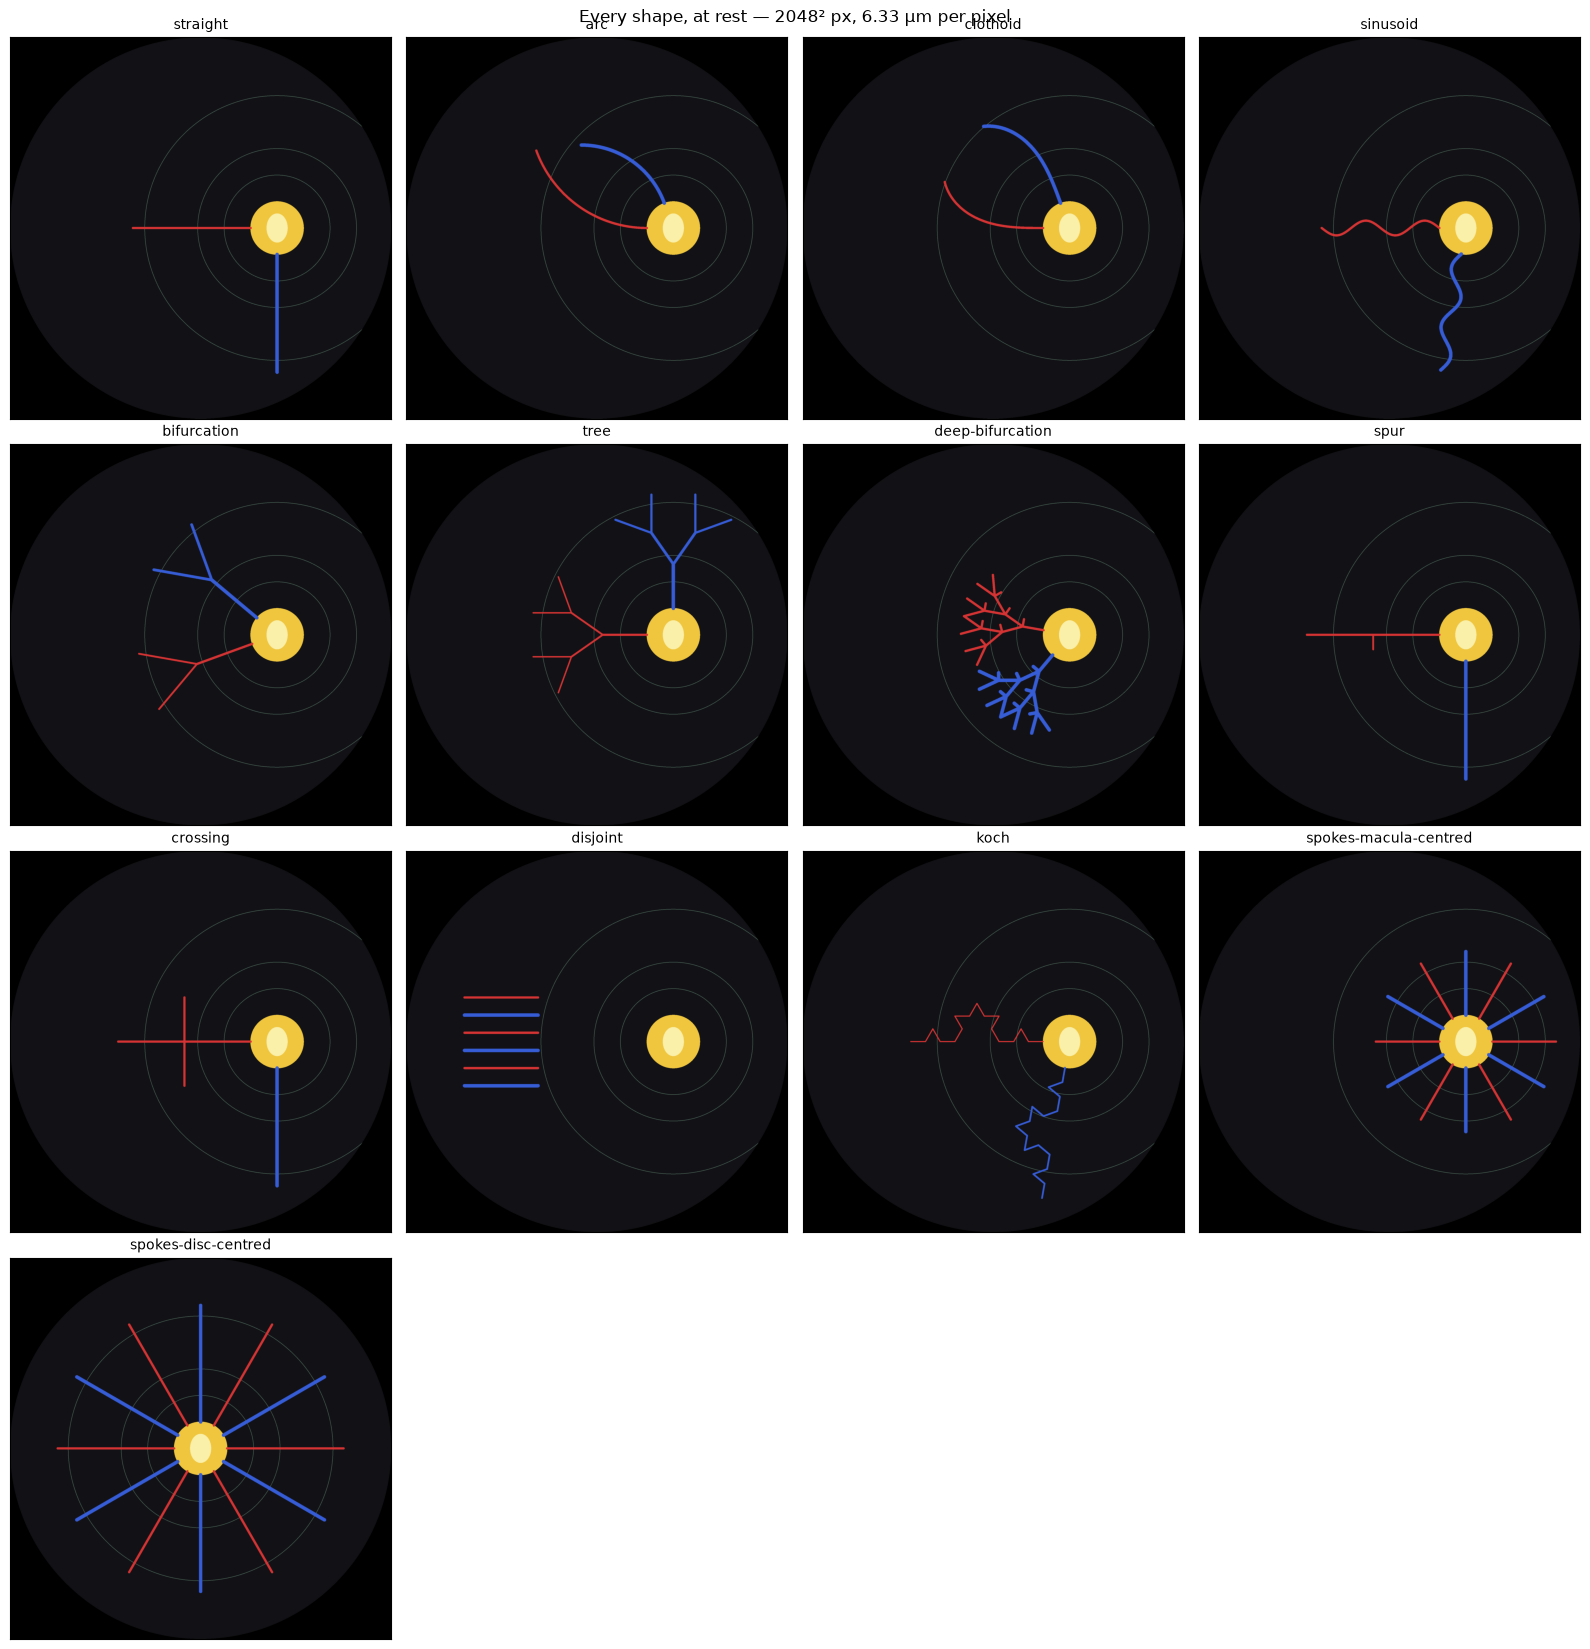

In [2]:
def picture(key: str, axis, title: str | None = None) -> None:
    """One stored rendering, exactly as an implementation is handed it."""
    rendering = store.load(STORE, key)
    axis.imshow(library.demo_image(rendering))
    axis.set_title(title or f"{rendering.family}\n{rendering.rotation:g}°", fontsize=10)
    axis.set_xticks([])
    axis.set_yticks([])


at_rest = [f"{family}-{SIDE}-000" for family in FAMILIES]
columns = 4
rows = math.ceil(len(at_rest) / columns)
fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 4.2 * rows))
for axis in axes.ravel()[len(at_rest):]:
    axis.set_visible(False)
for axis, key in zip(axes.ravel(), at_rest):
    picture(key, axis, title=manifest.loc[key, "family"])
fig.suptitle(f"Every shape, at rest — {SIDE}² px, {UM_PER_PX:.3g} µm per pixel", fontsize=12)
fig.tight_layout()

### 1.1 The same shape, turned

Every angle the store holds, of one shape. The vessels do not change; only which pixels they land
on does. A measurement that moves across this row is reading the lattice rather than the retina.

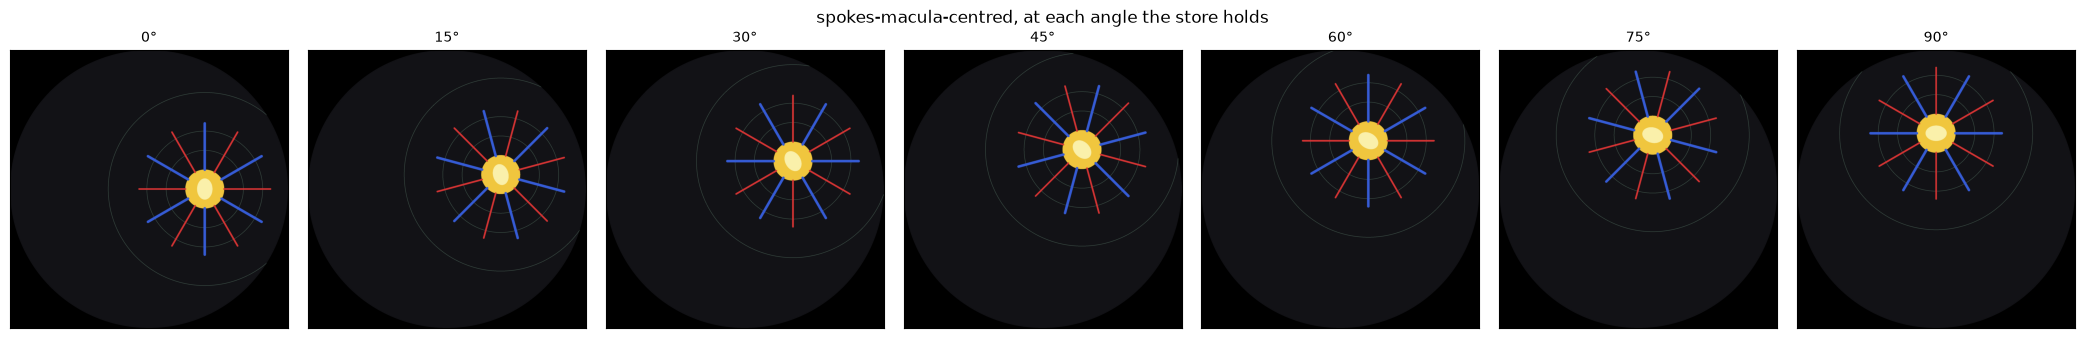

In [3]:
family = "spokes-macula-centred"
fig, axes = plt.subplots(1, len(ROTATIONS), figsize=(3 * len(ROTATIONS), 3.4))
for axis, angle in zip(np.atleast_1d(axes), ROTATIONS):
    picture(f"{family}-{SIDE}-{round(angle):03d}", axis, title=f"{angle:g}°")
fig.suptitle(f"{family}, at each angle the store holds", fontsize=12)
fig.tight_layout()

## 2. What each shape settles

This is `ground_truth.csv` and `ground_truth_kind.csv`, read back, keyed
`family / biomarker / structure / [region] / [statistic]` after
[BIOMARKER-NAMES.md](../../docs/BIOMARKER-NAMES.md) — so a number an implementation returns is compared
with the right definition rather than with whichever happens to share its name.

Every value is derived over **the field of view, zone B and zone C**, for **arteries, veins, the
vessels as one class** and, for the ratios, **both**. Where a biomarker is not defined over both
classes at once the vocabulary does not carry the union name and the shape does not invent one.

**Every value says how it is known**:

| Kind | Means |
| --- | --- |
| `exact` | a closed form, or integrated from the geometry to far below any measurement's error |
| `numerical` | averaged on a 20 µm grid — sparsity, the distance from the retina to its nearest vessel |
| `asymptotic` | a limit no finite raster reaches: a fractal dimension |
| `convention` | rests on a reading of the definition the geometry alone does not settle — a crossing read as two vessels, a lone vessel passed through Knudtson's pairing |

**Three different things, kept apart:**

- **a value** — what the geometry requires;
- **no value** — the geometry says there is nothing to measure: no junction to take an angle at, no
  piece of vessel in zone C to pool. An implementation is right to return nothing, and wrong to
  return a number;
- **nothing settled** — the shape says nothing about it, such as a Koch curve's squared curvature,
  infinite at every corner.

**Every length is in microns**, never pixels: an area in µm², a curvature in 1/µm. The values do not
depend on the angle, so one column per shape is enough.

In [4]:
counted = []
for family in FAMILIES:
    key = f"{family}-{SIDE}-000"

    def steady(values: dict) -> dict:
        # The vertical and horizontal cup-to-disc ratios read the image's axes, so turning the
        # photograph is *meant* to move them; everything else must not move.
        return {k: v for k, v in values.items() if k not in derive.TURN_WITH_THE_IMAGE}

    assert all(
        steady(truth[f"{family}-{SIDE}-{round(angle):03d}"]) == steady(truth[key])
        and kinds[f"{family}-{SIDE}-{round(angle):03d}"] == kinds[key]
        for angle in ROTATIONS
    ), f"{family}: a rotation changed what the geometry requires, which it must never do"
    known = pd.Series(kinds[key])
    valued = known[[name in truth[key] for name in known.index]]
    counted.append(
        {
            "shape": family,
            **valued.value_counts().reindex(derive.KINDS, fill_value=0).to_dict(),
            "no value": len(undefined[key]),
            "settled in all": len(known),
        }
    )
settled = pd.DataFrame(counted).set_index("shape")
names = sorted({name for key in kinds for name in kinds[key]})
print(f"{len(names)} canonical names settled somewhere; "
      f"{int(settled['settled in all'].sum())} settled across {len(FAMILIES)} shapes")
settled

928 canonical names settled somewhere; 11144 settled across 13 shapes


,exact,numerical,asymptotic,convention,no value,settled in all
shape,,,,,,
straight,844,18,36,12,18,928
arc,844,18,36,12,18,928
clothoid,844,18,36,12,18,928
sinusoid,844,18,36,12,18,928
bifurcation,736,18,36,12,6,808
tree,682,18,36,12,0,748
deep-bifurcation,670,18,36,24,0,748
spur,770,18,36,12,12,848
crossing,442,18,36,414,18,928


### 2.1 The values, for arteries over the field of view

Every shape's artery values over the whole field, as one table: the veins, the union and the zones
follow the same derivations and are in the CSV. A blank is a value the shape settles nothing about;
**`—` is one it settles as having none**.

In [5]:
def cell(key: str, name: str):
    if name in truth[key]:
        return truth[key][name]
    return "—" if name in kinds[key] else np.nan


artery = [
    name for name in names
    if name.split("/")[2:3] == ["artery"] and not set(name.split("/")) & {"B", "C"}
]
table = pd.DataFrame(
    {family: [cell(f"{family}-{SIDE}-000", name) for name in artery] for family in FAMILIES},
    index=pd.Index(artery, name="biomarker / artery / [statistic]"),
)
pd.set_option("display.max_rows", 400)
table.map(lambda v: round(v, 4) if isinstance(v, float) else v)

,straight,arc,clothoid,sinusoid,bifurcation,tree,deep-bifurcation,spur,crossing,disjoint,koch,spokes-macula-centred,spokes-disc-centred
biomarker / artery / [statistic],,,,,,,,,,,,,
calibre/width/artery/length-weighted,80.0,80.0,80.0,80.0,68.9974,58.8337,80.0000,78.0000,80.0,80.0,40.0,80.0,80.0
calibre/width/artery/mean,80.0,80.0,80.0,80.0,68.9974,58.3685,80.0000,73.3333,80.0,80.0,40.0,80.0,80.0
calibre/width/artery/median,80.0,80.0,80.0,80.0,63.4960,50.3968,80.0000,80.0000,80.0,80.0,40.0,80.0,80.0
calibre/width/artery/std,0.0,0.0,0.0,0.0,7.7800,10.5200,0.0000,9.4281,0.0,0.0,0.0,0.0,0.0
density/area/artery,325024.5299,395978.2815,325024.5284,369772.9359,417351.8279,548810.2500,983393.1657,394037.6789,603649.0597,615073.5896,319669.7241,1066947.1791,1930947.1791
density/box-counting/artery,1.0,1.0,1.0,1.0,1.0000,1.0000,1.0000,1.0000,1.0,1.0,1.2619,1.0,1.0
density/multifractal-d0/artery,1.0,1.0,1.0,1.0,1.0000,1.0000,1.0000,1.0000,1.0,1.0,1.2619,1.0,1.0
density/multifractal-d1/artery,1.0,1.0,1.0,1.0,1.0000,1.0000,1.0000,1.0000,1.0,1.0,1.2619,1.0,1.0
density/multifractal-d2/artery,1.0,1.0,1.0,1.0,1.0000,1.0000,1.0000,1.0000,1.0,1.0,1.2619,1.0,1.0


## 3. The derivations

Each value above follows from the geometry, and each is stated here so that a reader can disagree
with the arithmetic rather than with the code (`src/benchmarks/shapes/truth.py`).

**Every centreline is sampled every 0.5 µm**, with its curvature carried exactly rather than
differenced out of the points, so integrals along it are exact to far below anything a rendering
resolves. **Regions are clipped in continuous coordinates**: a vessel crossing zone B is cut where it
enters and leaves the annulus, and only what lies inside is pooled.

### 3.1 Straight vessel

Tortuosity is **exactly 1** under any arc-over-chord definition, because the arc *is* the chord;
total curvature is **exactly 0**. Its area is the width times the length plus a disc of that width
for the two rounded ends — the two-dimensional tube formula. A lone vessel crossing zone B gives
Knudtson's equivalent as its own width, passed through the recursion untouched — a reading of the
formula, so `convention` — and Hubbard's, which combines a pair, likewise.

### 3.2 Circular arc

Curvature is **exactly 1/r**. Arc length is `rθ`, the chord `2r sin(θ/2)`, so

$$\tau_1 = \frac{\theta}{2\sin(\theta/2)}$$

in which **`r` cancels**: the artery and vein bend through the same 70° about different radii, so τ1
must come back equal for both while `∫κ² ds = θ/r` must not.

### 3.3 Clothoid

An Euler spiral: curvature rising linearly from 0 to `κ` along its length `L`, so
`∫κ ds = κL/2` and `∫κ² ds = κ²L/3`. It separates a measure that integrates curvature from one that
reads it at the ends or at its peak.

### 3.4 Sinusoid

Its arc length is an elliptic integral with no elementary closed form, so the value *is* the sum
along the sampled curve, with `κ = y″ / (1 + y′²)^{3/2}` exact at every sample. It is the shape whose
curvature changes sign — three times over two wavelengths — so it settles the inflection count and
Grisan's density, both zero on every curve that bends one way.

### 3.5 Bifurcation and tree

A trunk from the disc forking symmetrically, its daughters narrowed by **Murray's law** — each
`2^(−1/3)` of its parent's width — so the widths pooled over the class are two (or three) different
numbers, and the mean, median and length-weighted mean are three different answers. One junction and
three ends for the fork; three junctions and five ends for the two-generation tree. A **whole vessel**
runs from the root to a tip and turns at each fork by half the fork's angle, so `vessel-` tortuosity
differs from per-segment tortuosity, and the squared curvature of a whole vessel — infinite at the
corner — is not settled.

### 3.6 Deep tree

Three generations of forks at one width, with a stub off every junction: seven junctions of four
branches each, sixteen ends. Which two of a junction's four branches are *the* daughters is a reading
of the definition, so its branching angle is a `convention`.

### 3.7 Spur

A straight artery with a 500 µm side branch at right angles halfway along: one junction, three ends,
a branching angle of 90°. The branch is shorter than the shortest leaf several implementations keep,
so the definition counts it and a length filter drops it — and the difference is the finding.

### 3.8 Crossing

An artery from the disc crossed at right angles by an artery that never reaches it. Two vessels over
one another, not a junction — but a skeleton cannot tell, so every count, rooted length, whole vessel
and equivalent that rests on that reading is a `convention`, while widths and areas stay `exact`.

### 3.9 Parallel vessels that never meet

Orphans: no vessel reaches the disc, so the rooted length is 0, there are **no whole vessels** and
every `vessel-` value is *no value*, and nothing crosses zone B or C. It shows whether a measurement
quietly requires a vessel to reach the disc before it counts it.

### 3.10 Koch curve

Two generations of the Koch construction at half the usual width. Its arc over chord is `(4/3)²`,
and its similarity dimension `log 4 / log 3` — the value every box-counting and multifractal
dimension tends to, which no finite raster reaches, so `asymptotic`. Every other shape is smooth and
tends to dimension 1. Its corners make the squared curvature infinite, so τ3, τ5 and τ7, Grisan's
density and spline curvature are not settled here.

### 3.11 Spokes from the disc

Six arteries and six veins radiate from the disc margin, alternating every 30°. On the disc-centred
frame they reach 5.4 disc radii, crossing all of zone B and zone C; on the macula-centred frame 3.4,
which is all of zone B. Every vessel of a class shares a width, so Knudtson's recursion — the six
widest, widest paired with narrowest, each pair `k·√(w₁² + w₂²)` with `k` 0.88 for arterioles and
0.95 for venules — gives the same answer whatever order an implementation pairs them in. The two
framings photograph **the same eye**, so every zone-B value must agree between them; and the
centring follows from where the disc sits — `disc` within 10% of the field's diameter of the frame
centre, `macula` otherwise.

### 3.12 The vessels as one class

The union is derived on both networks together, exactly as an implementation measuring the vessels
as one class would see them. Where the two classes touch, the union's topology rests on how a
crossing of two classes is read and is marked `convention`; in these shapes they never do.

### 3.13 The optic disc and cup

Every shape carries the same optic nerve head: a disc 1,800 µm across and, on its centre, a cup
drawn as an ellipse whose horizontal and vertical diameters are **0.40 and 0.55** of the disc's.
They are unequal on purpose: a vertical and a horizontal ratio that were swapped would show it.

A cup-to-disc ratio is read along the image's rows or columns. The cup turns with the photograph,
so its extent along a column is the half-width of its turned bounding box:

- **vertical** = `√((0.40·sin θ)² + (0.55·cos θ)²)`, 0.55 upright and 0.40 at 90°;
- **horizontal** = `√((0.40·cos θ)² + (0.55·sin θ)²)`, the other way round;
- **area** = `0.40 × 0.55 = 0.22` at every angle.

So the vertical and horizontal ratios are the two values in this store that are **meant** to move
with the rotation, and the analysis leaves them out of the rotation check; the area ratio must not
move. All three are `exact`. The disc is a circle, so its own extent is its diameter at every angle.


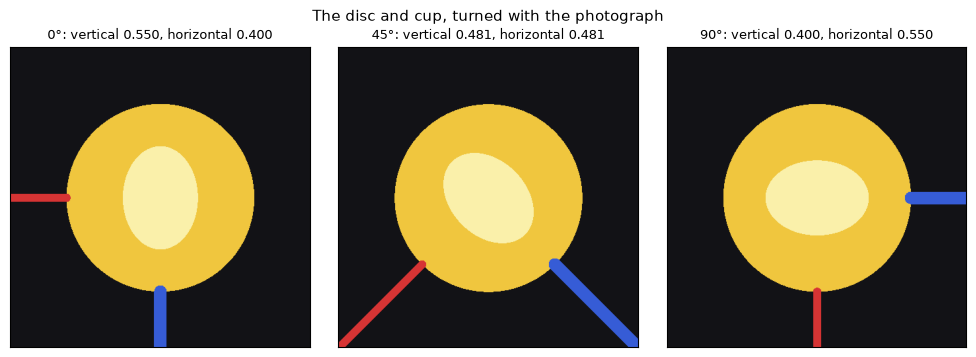

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for axis, angle in zip(axes, (0, 45, 90), strict=True):
    rendering = store.load(STORE, f"straight-{SIDE}-{angle:03d}")
    x, y, radius = rendering.disc
    half = int(1.6 * radius)
    rows = slice(int(y) - half, int(y) + half)
    cols = slice(int(x) - half, int(x) + half)
    axis.imshow(library.demo_image(rendering, rings=False)[rows, cols])
    ratios = derive.cup_ratios(library.scene("straight"), float(angle))
    axis.set_title(
        f"{angle}°: vertical {ratios['landmarks/CDR-vertical'].value:.3f}, "
        f"horizontal {ratios['landmarks/CDR-horizontal'].value:.3f}",
        fontsize=9,
    )
    axis.set_xticks([])
    axis.set_yticks([])
fig.suptitle("The disc and cup, turned with the photograph", fontsize=11)
fig.tight_layout()

## 4. A rasterised shape is not the shape

The theory describes a continuous curve; an implementation sees pixels. The difference is real and
is nobody's bug. Below: the area actually drawn, against the area the geometry requires, as the grid
refines — **the frame always spans the same 45° field, so a finer grid is a finer scale**, and the
artery grows from six pixels across to twenty-five.

**Expect a sawtooth, not a smooth curve.** What separates the two is at most one row of pixels along
the vessel, and whether that row is taken depends on where the centreline falls between pixel
centres. Read the trend across four grids, never the step between two.

In [7]:
rows = []
required = library.truths("straight")["density/area/artery"].value
for side in (1024, 1536, 2048, 4096):
    # Built rather than read: the store holds one grid, and this asks what changes between grids.
    shape = library.build("straight", side=side)
    # The mask is pixels and the theory is µm², so the drawn area is converted before the two are
    # compared — by `canonical.from_pixels`, the one rule that does this anywhere in the repository.
    drawn = canonical.from_pixels("density/area/artery", float(shape.artery.sum()), shape.um_per_px)
    width = scene.ARTERY_UM / shape.um_per_px
    rows.append(
        {
            "side": side,
            "µm per pixel": shape.um_per_px,
            "artery width, px": round(width, 1),
            "area drawn, µm²": drawn,
            "area geometry requires, µm²": required,
            "relative difference": drawn / required - 1.0,
            "one row of pixels would be": 1.0 / width,
        }
    )
pd.DataFrame(rows).set_index("side").round(4)

,µm per pixel,"artery width, px","area drawn, µm²","area geometry requires, µm²",relative difference,one row of pixels would be
side,,,,,,
1024,12.6562,6.3,308828.3203,325024.5299,-0.0498,0.1582
1536,8.4375,9.5,342715.4297,325024.5299,0.0544,0.1055
2048,6.3281,12.6,308828.3203,325024.5299,-0.0498,0.0791
4096,3.1641,25.3,334096.8201,325024.5299,0.0279,0.0396


## 5. The one place the scale matters

**No canonical value moves with the resolution.** Every length here is in microns, so photographing
the same retina on a coarser or finer grid gives the same number for every one of them — the widths
in pixels move, and the scale is divided back out. That is the whole reason the vocabulary refuses
pixels: a calibre of 8 px means nothing without the camera that took it.

**But the scale still decides where a formula may be evaluated**, and the two central retinal
equivalents differ exactly there:

- **Knudtson** combines each pair as `k·√(w₁² + w₂²)`. It is purely multiplicative and therefore
  scale-*free*: fed pixel widths it answers in pixels, and the same conversion turns one into the
  other.
- **Hubbard** combines them as `√(a·w₁² + b·w₂² + c·w₁w₂ + d)` with coefficients fitted in
  **microns** — and the additive `d`, −10.76 for arterioles and +450.05 for venules, **does not
  scale**. Fed pixels it returns a different quantity wearing the same name, and no conversion
  afterwards can repair it. The last columns below are what that looks like: Hubbard's formula
  evaluated on pixel widths and converted as though it were a length, disagreeing with the right
  answer by more the coarser the camera — and far more for veins, whose constant is the larger.

**The three arteriovenous ratios are three different numbers on the same vessels** — the plain
ratio of calibres, Knudtson's, and Hubbard's.

In [8]:
settles = {
    name: {key: t.value for key, t in library.truths(name).items()}
    for name in ("spokes-macula-centred", "spokes-disc-centred")
}
rows = []
for side in (1024, 2048, 4096):
    um = render.um_per_px(side)
    for vessel, width in (("artery", scene.ARTERY_UM), ("vein", scene.VEIN_UM)):
        right = derive.hubbard([width] * 6, vessel)
        # The mistake, done deliberately so its size can be read off: Hubbard on pixel widths,
        # then converted as though its answer were an ordinary length.
        on_pixels = derive.hubbard([width / um] * 6, vessel) * um
        rows.append(
            {
                "side": side,
                "µm per pixel": um,
                "class": vessel,
                "width, px": width / um,
                "CRE Knudtson, µm": derive.knudtson([width] * 6, vessel),
                "CRE Hubbard, µm": right,
                "Hubbard on pixels, µm": on_pixels,
                "error if computed on pixels": on_pixels / right - 1.0,
            }
        )
display(pd.DataFrame(rows).set_index(["side", "class"]).round(4))
pd.DataFrame(
    {
        name: {
            "AVR, calibres": values["calibre/AVR-ratio/both"],
            "AVR, Knudtson, zone B": values["calibre/AVR-knudtson/both/B"],
            "AVR, Hubbard, zone B": values["calibre/AVR-hubbard/both/B"],
        }
        for name, values in settles.items()
    }
).round(4)

µm per pixel  width, px  CRE Knudtson, µm  CRE Hubbard, µm  \
side class                                                                
1024 artery       12.6562     6.3210          139.8744         151.7217   
     vein         12.6562     9.4815          256.5133         224.9846   
2048 artery        6.3281    12.6420          139.8744         151.7217   
     vein          6.3281    18.9630          256.5133         224.9846   
4096 artery        3.1641    25.2840          139.8744         151.7217   
     vein          3.1641    37.9259          256.5133         224.9846   

             Hubbard on pixels, µm  error if computed on pixels  
side class                                                       
1024 artery               127.4729                      -0.1598  
     vein                 568.4234                       1.5265  
2048 artery               146.1437                      -0.0368  
     vein                 342.7185                       0.5233  
4096 artery               150.4526                      -0.0084  
     vein                 256.9897                       0.1423

,spokes-macula-centred,spokes-disc-centred
"AVR, calibres",0.6667,0.6667
"AVR, Knudtson, zone B",0.5453,0.5453
"AVR, Hubbard, zone B",0.6744,0.6744


## 6. What this benchmark does not test

- **How a cup is found.** Every adapter is now handed the drawn cup (§3.13), so what is tested is
  the arithmetic from a cup mask to a ratio, not the segmentation that produced the mask. Finding a
  cup in a photograph is measured against ophthalmologists' own outlines in the
  [disc benchmark](../../docs/benchmarks/disc-results.md).
- **Anything anchored to the fovea** — the disc-fovea distance, and the temporal angle — because a
  synthetic shape has no macula and inventing one would make the answer a property of the fixture.
- **Vessel tracing**, which is a step rather than a number.
- **Whether an implementation works on a photograph.** A program that measures a synthetic vessel
  exactly may still fail on a segmentation of a real eye, which is the next benchmark's question.